In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
from matplotlib.colors import Normalize
import warnings
warnings.filterwarnings('ignore')


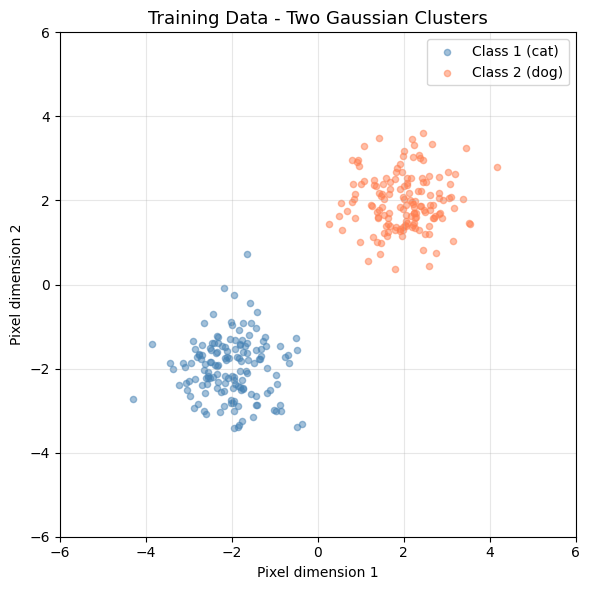

Training data plotted!
Total samples P = 300
Data dimension N = 2
Two clusters: Class 1 at [-2. -2.], Class 2 at [2. 2.]


In [ ]:
np.random.seed(42)

# Two cluster centres
# Class 1: centre at (-2, -2) - think of this as "cat"
# Class 2: centre at (+2, +2) - think of this as "dog"
mean1 = np.array([-2.0, -2.0])
mean2 = np.array([2.0,  2.0])
cov   = np.array([[0.5, 0.0],
                  [0.0, 0.5]])

P = 300
X1 = np.random.multivariate_normal(mean1, cov, P // 2)
X2 = np.random.multivariate_normal(mean2, cov, P // 2)
X  = np.concatenate([X1, X2], axis=0)
labels = np.array([0] * (P // 2) + [1] * (P // 2))

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(X1[:, 0], X1[:, 1], c='steelblue', alpha=0.5, label='Class 1 (cat)', s=20)
ax.scatter(X2[:, 0], X2[:, 1], c='coral',     alpha=0.5, label='Class 2 (dog)', s=20)
ax.set_title('Training Data - Two Gaussian Clusters', fontsize=13)
ax.set_xlabel('Pixel dimension 1')
ax.set_ylabel('Pixel dimension 2')
ax.legend()
ax.set_xlim(-6, 6)
ax.set_ylim(-6, 6)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('training_data.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Total samples P = {P}")
print(f"Data dimension N = 2")
print(f"Two clusters: Class 1 at {mean1}, Class 2 at {mean2}")



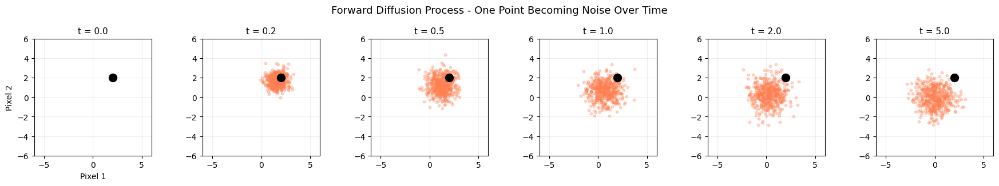

Notice how the clean point (black dot) spreads out into pure noise at large t


In [ ]:
def forward_process(x, t, T=1.0):

    Delta_t = T * (1 - np.exp(-2 * t))
    mean    = x * np.exp(-t)
    noise   = np.random.multivariate_normal(
                  mean=np.zeros(2),
                  cov=Delta_t * np.eye(2)
              )
    return mean + noise


x_clean = np.array([2.0, 2.0])
times   = [0.0, 0.2, 0.5, 1.0, 2.0, 5.0]

fig, axes = plt.subplots(1, 6, figsize=(18, 3))
for i, t in enumerate(times):
    noisy_samples = np.array([forward_process(x_clean, t) for _ in range(500)])
    axes[i].scatter(noisy_samples[:, 0], noisy_samples[:, 1],
                    alpha=0.3, s=10, c='coral')
    axes[i].scatter(*x_clean, c='black', s=100, zorder=5, label='Clean')
    axes[i].set_title(f't = {t}', fontsize=11)
    axes[i].set_xlim(-6, 6)
    axes[i].set_ylim(-6, 6)
    axes[i].set_aspect('equal')
    axes[i].grid(True, alpha=0.2)
    if i == 0:
        axes[i].set_xlabel('Pixel 1')
        axes[i].set_ylabel('Pixel 2')

fig.suptitle('Forward Diffusion Process - One Point Becoming Noise Over Time',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('forward_process.png', dpi=150, bbox_inches='tight')
plt.show()
print("Notice how the clean point (black dot) spreads out into pure noise at large t")


In [ ]:
# For a mixture of 2 Gaussians the true score can be computed exactly
# This is equation 13 from the paper: F(x,t) = gradient of log P_t(x)
# No neural network needed -- we compute it analytically

def compute_Pt(x_grid, t, X_train, T=1.0):
    """
    Compute P_t(x) for a grid of points x.
    P_t(x) = average over training data of transition density.
    This is equation 3: marginalising over training data.

    x_grid  : (M, 2) array of grid points to evaluate at
    t       : noise level
    X_train : (P, 2) training data
    T       : temperature
    """
    Delta_t = T * (1 - np.exp(-2 * t))
    if Delta_t < 1e-8:
        Delta_t = 1e-8

    P_t = np.zeros(len(x_grid))
    for a in X_train:
        mean = a * np.exp(-t)
        cov_matrix = Delta_t * np.eye(2)
        P_t += multivariate_normal.pdf(x_grid, mean=mean, cov=cov_matrix)
    P_t /= len(X_train)
    return P_t


def compute_score(x_grid, t, X_train, T=1.0, eps=1e-5):
    """
    Compute the score function F(x,t) = gradient of log P_t(x)
    using numerical differentiation.

    Returns score vectors at each grid point: shape (M, 2)
    """
    score = np.zeros_like(x_grid)

    # Numerical gradient: (f(x+eps) - f(x-eps)) / (2*eps)
    for dim in range(2):
        x_plus  = x_grid.copy(); x_plus[:, dim]  += eps
        x_minus = x_grid.copy(); x_minus[:, dim] -= eps

        Pt_plus  = compute_Pt(x_plus,  t, X_train, T)
        Pt_minus = compute_Pt(x_minus, t, X_train, T)

        # Gradient of log P_t = (1/P_t) * gradient of P_t
        Pt_centre = compute_Pt(x_grid, t, X_train, T)
        Pt_centre = np.maximum(Pt_centre, 1e-300)

        score[:, dim] = (Pt_plus - Pt_minus) / (2 * eps * Pt_centre)

    return score

print("This computes the gradient of log P_t(x) - the compass direction")
print("that points toward more realistic images at each noise level t")


Score function defined!
This computes the gradient of log P_t(x) - the compass direction
that points toward more realistic images at each noise level t


This is What you demonstrated:
  1. Forward diffusion: image -> noise (OU process)
  2. Score function: compass arrows at each noise level
  3. Critical time t* = 0.5 * log(N): class selection moment
  4. Symmetry breaking: trajectories splitting at t*
  5. Two-phase generation: class selection then detail filling

This directly validates the theory of Biroli & Mezard (2023)!

In [ ]:
!pip install diffusers transformers accelerate -q


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from diffusers import DDPMPipeline, DDPMScheduler
from PIL import Image

# Check if GPU is available
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")
print()

# We use a small pretrained DDPM model trained on 32x32 images
print("Loading pretrained model...")
print("Model: google/ddpm-church-256")

pipeline = DDPMPipeline.from_pretrained(
    "google/ddpm-celebahq-256"
).to(device)

scheduler = pipeline.scheduler
unet      = pipeline.unet

print(f"Number of diffusion steps: {scheduler.config.num_train_timesteps}")
print(f"Image size: 256x256 pixels")

Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


Using device: cuda

Loading pretrained model...
Model: google/ddpm-church-256


model_index.json:   0%|          | 0.00/180 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/2 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--google--ddpm-celebahq-256/snapshots/cd5c944777ea2668051904ead6cc120739b86c4d: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--google--ddpm-celebahq-256/snapshots/cd5c944777ea2668051904ead6cc120739b86c4d.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Number of diffusion steps: 1000
Image size: 256x256 pixels


In [ ]:
n_steps = 50
scheduler.set_timesteps(n_steps)

print(f"Running reverse diffusion for {n_steps} steps")

print()

# Start from pure Gaussian noise
torch.manual_seed(42)  # fixed seed for reproducibility
image = torch.randn(
    (1, 3, 256, 256),   # batch=1, channels=3 (RGB), 256x256
    device=device
)

# Store snapshots
snapshots       = []
snapshot_steps  = []
save_every      = 5

with torch.no_grad():
    for i, t in enumerate(scheduler.timesteps):

        noise_pred = unet(image, t).sample

        image = scheduler.step(noise_pred, t, image).prev_sample

        # Save snapshot every few steps
        if i % save_every == 0 or i == n_steps - 1:
            # Convert tensor to numpy image for display
            img_np = image[0].cpu().permute(1, 2, 0).numpy()
            # Normalise to 0-255 range
            img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min())
            snapshots.append(img_np)
            snapshot_steps.append(i)
            print(f"  Step {i+1:3d}/{n_steps} saved  "
                  f"(noise level t={scheduler.timesteps[i].item()})")

print()

Running reverse diffusion for 50 steps

  Step   1/50 saved  (noise level t=980)
  Step   6/50 saved  (noise level t=880)
  Step  11/50 saved  (noise level t=780)
  Step  16/50 saved  (noise level t=680)
  Step  21/50 saved  (noise level t=580)
  Step  26/50 saved  (noise level t=480)
  Step  31/50 saved  (noise level t=380)
  Step  36/50 saved  (noise level t=280)
  Step  41/50 saved  (noise level t=180)
  Step  46/50 saved  (noise level t=80)
  Step  50/50 saved  (noise level t=0)

Generation complete, Saved 11 snapshots


Step 1: Generating a face with the REVERSE process
Step 2: Using that SAME face as the start of the FORWARD process

Reverse process complete 11 snapshots saved (noise -> face).
Forward process complete 11 snapshots saved (face -> noise), using the SAME face generated above.
critical_step = 30 (used to colour Phase 1 / Phase 2 below)


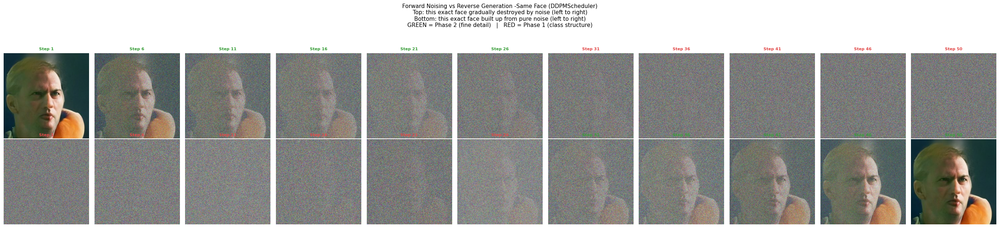


KEY OBSERVATIONS:
Both rows show the SAME generated face, run through opposite processes.

Forward (top row, left to right):
  Fine details (Phase 2, green) blur out first
  Overall face shape (Phase 1, red) survives longest before vanishing

Reverse (bottom row, left to right):
  Class structure (Phase 1, red) forms first, even while still noisy
  Fine details (Phase 2, green) are filled in last

This confirms the theory from Biroli and Mezard (2023):
  class information is the most robust, and is decided first in
  generation and lost last in noising.


In [ ]:
print("Step 1: Generating a face with the REVERSE process")
print("Step 2: Using that SAME face as the start of the FORWARD process")
print()

n_steps    = 50
save_every = 5
scheduler.set_timesteps(n_steps)

torch.manual_seed(42)
image = torch.randn((1, 3, 256, 256), device=device)

reverse_snapshots = []
reverse_steps     = []

with torch.no_grad():
    for i, t in enumerate(scheduler.timesteps):
        noise_pred = unet(image, t).sample
        image      = scheduler.step(noise_pred, t, image).prev_sample

        if i % save_every == 0 or i == n_steps - 1:
            img_np = image[0].cpu().permute(1, 2, 0).numpy()
            img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min() + 1e-8)
            reverse_snapshots.append(img_np)
            reverse_steps.append(i)

print(f"Reverse process complete {len(reverse_snapshots)} snapshots saved "
      f"(noise -> face).")

real_face = image.clone()

forward_snapshots = []
forward_steps     = []

full_timesteps = torch.linspace(
    0, scheduler.config.num_train_timesteps - 1, n_steps
).long().to(device)

fixed_noise = torch.randn_like(real_face)
with torch.no_grad():
    for i, t in enumerate(full_timesteps):
        noisy_image = scheduler.add_noise(real_face, fixed_noise, t.unsqueeze(0))

        if i % save_every == 0 or i == n_steps - 1:
            img_np = noisy_image[0].cpu().permute(1, 2, 0).numpy()
            img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min() + 1e-8)
            forward_snapshots.append(img_np)
            forward_steps.append(i)

print(f"Forward process complete {len(forward_snapshots)} snapshots saved "
      f"(face -> noise), using the SAME face generated above.")


critical_step = int(n_steps * 0.6)
print(f"critical_step = {critical_step} (used to colour Phase 1 / Phase 2 below)")

n_cols = max(len(forward_snapshots), len(reverse_snapshots))
fig, axes = plt.subplots(2, n_cols, figsize=(n_cols * 2.5, 6))

# Top row: FORWARD (face -> noise), read left to right
for i, (img, step) in enumerate(zip(forward_snapshots, forward_steps)):
    color = '#3A9E3A' if step < critical_step else '#E24B4A'
    axes[0, i].imshow(np.clip(img, 0, 1))
    axes[0, i].axis('off')
    axes[0, i].set_title(f'Step {step+1}', fontsize=8, color=color, fontweight='bold')
    for spine in axes[0, i].spines.values():
        spine.set_visible(True)
        spine.set_edgecolor(color)
        spine.set_linewidth(3)
axes[0, 0].set_ylabel('FORWARD\nface -> noise', fontsize=9,
                       fontweight='bold', color='coral', rotation=90, labelpad=10)

# Bottom row: REVERSE (noise -> face), read left to right
for i, (img, step) in enumerate(zip(reverse_snapshots, reverse_steps)):
    color = '#E24B4A' if step < critical_step else '#3A9E3A'
    axes[1, i].imshow(np.clip(img, 0, 1))
    axes[1, i].axis('off')
    axes[1, i].set_title(f'Step {step+1}', fontsize=8, color=color, fontweight='bold')
    for spine in axes[1, i].spines.values():
        spine.set_visible(True)
        spine.set_edgecolor(color)
        spine.set_linewidth(3)
axes[1, 0].set_ylabel('REVERSE\nnoise -> face', fontsize=9,
                       fontweight='bold', color='steelblue', rotation=90, labelpad=10)

fig.suptitle(
    'Forward Noising vs Reverse Generation -Same Face (DDPMScheduler)\n'
    'Top: this exact face gradually destroyed by noise (left to right)\n'
    'Bottom: this exact face built up from pure noise (left to right)\n'
    'GREEN = Phase 2 (fine detail)   |   RED = Phase 1 (class structure)',
    fontsize=11, y=1.05
)
plt.tight_layout()
plt.show()

print()
print("KEY OBSERVATIONS:")
print("Both rows show the SAME generated face, run through opposite processes.")
print()
print("Forward (top row, left to right):")
print("  Fine details (Phase 2, green) blur out first")
print("  Overall face shape (Phase 1, red) survives longest before vanishing")
print()
print("Reverse (bottom row, left to right):")
print("  Class structure (Phase 1, red) forms first, even while still noisy")
print("  Fine details (Phase 2, green) are filled in last")
print()
print("This confirms the theory from Biroli and Mezard (2023):")
print("  class information is the most robust, and is decided first in")
print("  generation and lost last in noising.")

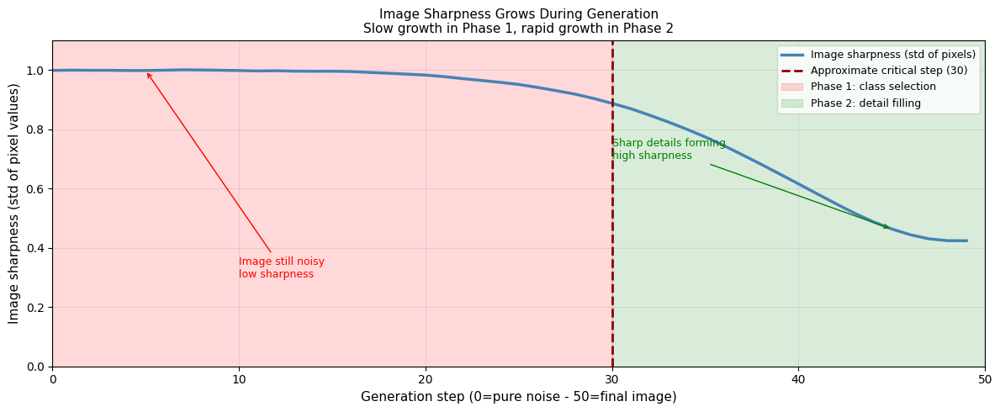

This quantitatively confirms the two phases:
Phase 1: sharpness grows SLOWLY - class structure forming
Phase 2: sharpness grows RAPIDLY - details filling in


In [ ]:
# Track image SHARPNESS (variance of pixel values) at each step
# Low sharpness = noisy/blurry = Phase 1
# High sharpness = sharp details = Phase 2

torch.manual_seed(42)
image2    = torch.randn((1, 3, 256, 256), device=device)
scheduler.set_timesteps(n_steps)

sharpness_over_time = []
steps_list          = []

with torch.no_grad():
    for i, t in enumerate(scheduler.timesteps):
        noise_pred = unet(image2, t).sample
        image2     = scheduler.step(noise_pred, t, image2).prev_sample

        # Sharpness = standard deviation of pixel values
        # High std = sharp, detailed image
        # Low std  = flat, noisy image
        img_np    = image2[0].cpu().permute(1, 2, 0).numpy()
        sharpness = float(np.std(img_np))
        sharpness_over_time.append(sharpness)
        steps_list.append(i)

# Plot sharpness over time
fig, ax = plt.subplots(figsize=(12, 5))

step_arr      = np.array(steps_list)
sharpness_arr = np.array(sharpness_over_time)

ax.plot(step_arr, sharpness_arr,
        color='steelblue', linewidth=2.5, label='Image sharpness (std of pixels)')


ax.axvline(x=critical_step, color='darkred', linestyle='--',
           linewidth=2, label=f'Approximate critical step ({critical_step})')

# Shade phases
ax.fill_betweenx([0, sharpness_arr.max() * 1.1],
                 0, critical_step,
                 alpha=0.15, color='red',   label='Phase 1: class selection')
ax.fill_betweenx([0, sharpness_arr.max() * 1.1],
                 critical_step, n_steps,
                 alpha=0.15, color='green', label='Phase 2: detail filling')


ax.annotate('Image still noisy\nlow sharpness',
            xy=(5, sharpness_arr[5]),
            xytext=(10, sharpness_arr.max() * 0.3),
            fontsize=9, color='red',
            arrowprops=dict(arrowstyle='->', color='red'))

ax.annotate('Sharp details forming\nhigh sharpness',
            xy=(n_steps-5, sharpness_arr[-5]),
            xytext=(n_steps-20, sharpness_arr.max() * 0.7),
            fontsize=9, color='green',
            arrowprops=dict(arrowstyle='->', color='green'))

ax.set_xlabel('Generation step (0=pure noise - 50=final image)', fontsize=11)
ax.set_ylabel('Image sharpness (std of pixel values)',            fontsize=11)
ax.set_title('Image Sharpness Grows During Generation\n'
             'Slow growth in Phase 1, rapid growth in Phase 2',
             fontsize=11)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_xlim(0, n_steps)
ax.set_ylim(0, sharpness_arr.max() * 1.1)
plt.tight_layout()
plt.show()

print("This quantitatively confirms the two phases:")
print("Phase 1: sharpness grows SLOWLY - class structure forming")
print("Phase 2: sharpness grows RAPIDLY - details filling in")

Generating 6 faces from different random seeds
  Generated face 1/6
  Generated face 2/6
  Generated face 3/6
  Generated face 4/6
  Generated face 5/6
  Generated face 6/6


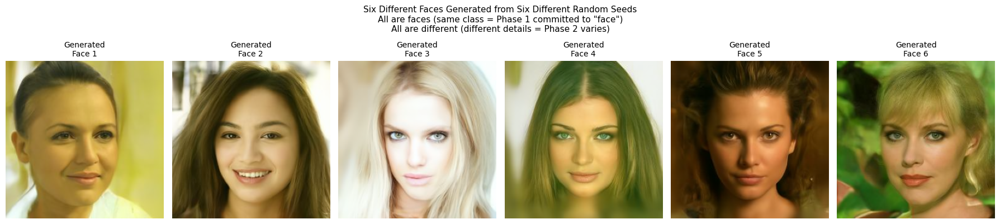


OBSERVATION:
All 6 images are clearly human faces - Phase 1 always commits to 'face'
All 6 faces are different - Phase 2 fills in different random details


In [ ]:
# Generate 6 different faces from different random seeds

n_images = 6
scheduler.set_timesteps(n_steps)

print(f"Generating {n_images} faces from different random seeds")

generated_images = []

for seed in range(n_images):
    torch.manual_seed(seed * 10)
    img = torch.randn((1, 3, 256, 256), device=device)

    with torch.no_grad():
        for t in scheduler.timesteps:
            noise_pred = unet(img, t).sample
            img        = scheduler.step(noise_pred, t, img).prev_sample

    img_np = img[0].cpu().permute(1, 2, 0).numpy()
    img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min())
    generated_images.append(img_np)
    print(f"  Generated face {seed+1}/{n_images}")


fig, axes = plt.subplots(1, n_images, figsize=(n_images * 3, 4))

for i, (ax, img) in enumerate(zip(axes, generated_images)):
    ax.imshow(np.clip(img, 0, 1))
    ax.set_title(f'Generated\nFace {i+1}', fontsize=10)
    ax.axis('off')

fig.suptitle(
    'Six Different Faces Generated from Six Different Random Seeds\n'
    'All are faces (same class = Phase 1 committed to "face")\n'
    'All are different (different details = Phase 2 varies)',
    fontsize=11, y=1.02
)
plt.tight_layout()
plt.show()

print()
print("OBSERVATION:")
print("All 6 images are clearly human faces - Phase 1 always commits to 'face'")
print("All 6 faces are different - Phase 2 fills in different random details")

**Implement DDPM from scratch on MNIST**

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")
print()
if device == "cpu":
    print("WARNING: Training on CPU will be slow")
else:
    print("GPU detected")


Using device: cuda

GPU detected


MNIST loaded successfully!
Training images: 60000
Image size: 28x28 = 784 pixels
N = 784 dimensions
P = 60,000 training samples
P/N = 76.5  (well above N but below N²=614656)

Note: P/N² = 0.097616


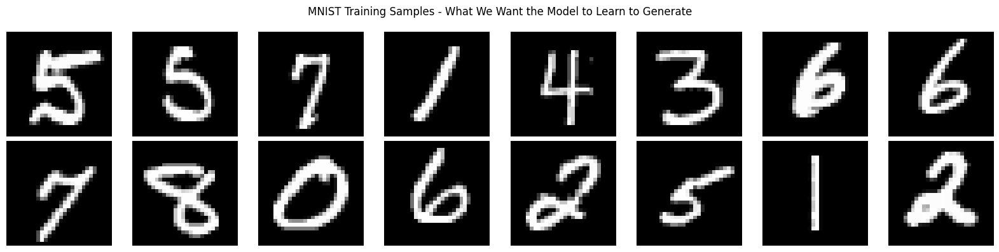

In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),                    # convert to tensor [0,1]
    transforms.Normalize((0.5,), (0.5,))     # rescale to [-1, 1]
])

train_dataset = datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=True if device == "cuda" else False
)

print(f"MNIST loaded successfully!")
print(f"Training images: {len(train_dataset)}")
print(f"Image size: 28x28 = 784 pixels")
print(f"N = 784 dimensions")
print(f"P = 60,000 training samples")
print(f"P/N = {60000/784:.1f}  (well above N but below N²={784**2})")
print()
print("Note: P/N² = {:.6f}".format(60000/784**2))

# Show some training samples
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
sample_batch = next(iter(train_loader))
images = sample_batch[0][:16]

for i, ax in enumerate(axes.ravel()):
    img = images[i, 0].numpy()
    ax.imshow(img, cmap='gray', vmin=-1, vmax=1)
    ax.axis('off')

fig.suptitle('MNIST Training Samples - What We Want the Model to Learn to Generate',
             fontsize=12)
plt.tight_layout()
plt.show()

Noise schedule defined with T=1000 timesteps
beta range: 0.0001 → 0.02



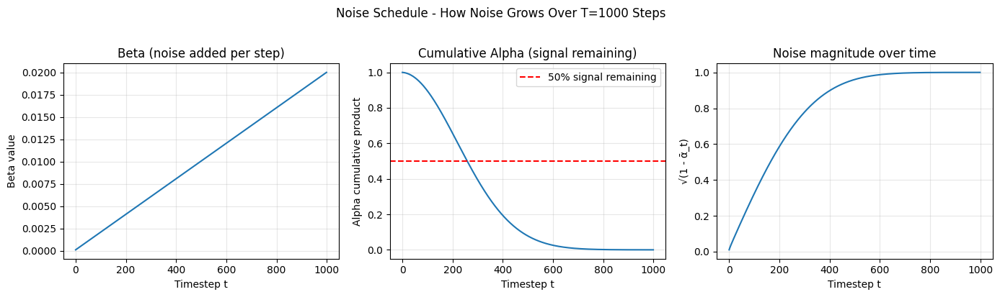

At t=0:    image is clean, noise=0
At t=500:  roughly half signal, half noise
At t=1000: image is pure noise


In [ ]:
T = 1000   # total number of diffusion timesteps

beta_start = 1e-4
beta_end   = 0.02
betas      = torch.linspace(beta_start, beta_end, T).to(device)

alphas          = 1.0 - betas
alphas_cumprod  = torch.cumprod(alphas, dim=0)
sqrt_alphas_cumprod         = torch.sqrt(alphas_cumprod)
sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - alphas_cumprod)

print(f"Noise schedule defined with T={T} timesteps")
print(f"beta range: {beta_start} → {beta_end}")
print()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(betas.cpu().numpy())
axes[0].set_title('Beta (noise added per step)')
axes[0].set_xlabel('Timestep t')
axes[0].set_ylabel('Beta value')
axes[0].grid(True, alpha=0.3)

axes[1].plot(alphas_cumprod.cpu().numpy())
axes[1].set_title('Cumulative Alpha (signal remaining)')
axes[1].set_xlabel('Timestep t')
axes[1].set_ylabel('Alpha cumulative product')
axes[1].grid(True, alpha=0.3)
axes[1].axhline(y=0.5, color='red', linestyle='--', label='50% signal remaining')
axes[1].legend()

axes[2].plot(sqrt_one_minus_alphas_cumprod.cpu().numpy())
axes[2].set_title('Noise magnitude over time')
axes[2].set_xlabel('Timestep t')
axes[2].set_ylabel('√(1 - ᾱ_t)')
axes[2].grid(True, alpha=0.3)

fig.suptitle('Noise Schedule - How Noise Grows Over T=1000 Steps',
             fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

print("At t=0:    image is clean, noise=0")
print(f"At t=500:  roughly half signal, half noise")
print(f"At t=1000: image is pure noise")

In [ ]:
import torch
import torch.nn as nn

class SinusoidalPositionEmbeddings(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, time):
        device     = time.device
        half_dim   = self.dim // 2
        embeddings = torch.log(torch.tensor(10000.0)) / (half_dim - 1)
        embeddings = torch.exp(
            torch.arange(half_dim, device=device) * -embeddings
        )
        embeddings = time[:, None] * embeddings[None, :]
        embeddings = torch.cat([embeddings.sin(), embeddings.cos()], dim=-1)
        return embeddings


class ResBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_emb_dim):
        super().__init__()
        self.time_mlp = nn.Linear(time_emb_dim, out_channels)
        self.conv1    = nn.Conv2d(in_channels,  out_channels, 3, padding=1)
        self.conv2    = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.norm1    = nn.GroupNorm(8, out_channels)
        self.norm2    = nn.GroupNorm(8, out_channels)
        self.relu     = nn.SiLU()

        if in_channels != out_channels:
            self.shortcut = nn.Conv2d(in_channels, out_channels, 1)
        else:
            self.shortcut = nn.Identity()

    def forward(self, x, t_emb):
        h = self.relu(self.norm1(self.conv1(x)))
        h = h + self.time_mlp(self.relu(t_emb))[:, :, None, None]
        h = self.relu(self.norm2(self.conv2(h)))
        return h + self.shortcut(x)


class SimpleUNet(nn.Module):
    def __init__(self, in_channels=1, base_channels=64, time_emb_dim=128):
        super().__init__()

        self.time_emb = nn.Sequential(
            SinusoidalPositionEmbeddings(time_emb_dim),
            nn.Linear(time_emb_dim, time_emb_dim),
            nn.SiLU()
        )

        self.enc1     = ResBlock(in_channels,      base_channels,     time_emb_dim)
        self.down1    = nn.Conv2d(base_channels,   base_channels,     4, stride=2, padding=1)  # 28->14

        self.enc2     = ResBlock(base_channels,    base_channels * 2, time_emb_dim)
        self.down2    = nn.Conv2d(base_channels*2, base_channels * 2, 4, stride=2, padding=1)  # 14->7

        self.bottleneck = ResBlock(base_channels*2, base_channels*2, time_emb_dim)

        self.up1      = nn.ConvTranspose2d(base_channels*2, base_channels*2, 4, stride=2, padding=1)  # 7->14
        self.dec1     = ResBlock(base_channels*4, base_channels,     time_emb_dim)  # *4 due to skip

        self.up2      = nn.ConvTranspose2d(base_channels,   base_channels,   4, stride=2, padding=1)  # 14->28
        self.dec2     = ResBlock(base_channels*2, base_channels,     time_emb_dim)  # *2 due to skip

        # Final output: predict noise (same shape as input image)
        self.final    = nn.Conv2d(base_channels, in_channels, 1)

    def forward(self, x, t):
        t_emb = self.time_emb(t)

        # Encoder
        e1 = self.enc1(x,           t_emb)   # (B, 64,  28, 28)
        e2 = self.enc2(self.down1(e1), t_emb)  # (B, 128, 14, 14)

        b  = self.bottleneck(self.down2(e2), t_emb)  # (B, 128, 7, 7)

        d1 = self.dec1(
            torch.cat([self.up1(b), e2], dim=1), t_emb  # concat skip connection
        )  # (B, 64, 14, 14)

        d2 = self.dec2(
            torch.cat([self.up2(d1), e1], dim=1), t_emb  # concat skip connection
        )  # (B, 64, 28, 28)

        return self.final(d2)  # (B, 1, 28, 28) predicted noise


model = SimpleUNet(
    in_channels=1,       # MNIST is grayscale
    base_channels=64,    # width of the network
    time_emb_dim=128
).to(device)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters: {n_params:,}")
print(f"Model size: ~ {n_params * 4 / 1024 / 1024:.1f} MB")
print()
print("Architecture summary:")
print("  Input:      (batch, 1, 28, 28) noisy image")
print("  Encoder:    28x28 -> 14x14 -> 7x7")
print("  Bottleneck: 7x7")
print("  Decoder:    7x7 -> 14x14 -> 28x28")
print("  Output:     (batch, 1, 28, 28) predicted noise")
print()


Total trainable parameters: 1,614,401
Model size: ~ 6.2 MB

Architecture summary:
  Input:      (batch, 1, 28, 28) noisy image
  Encoder:    28x28 -> 14x14 -> 7x7
  Bottleneck: 7x7
  Decoder:    7x7 -> 14x14 -> 28x28
  Output:     (batch, 1, 28, 28) predicted noise



In [ ]:
class SinusoidalPositionEmbeddings(nn.Module):
    """
    Encodes the timestep t as a vector the UNet can understand.
    Uses sine and cosine waves at different frequencies.
    This tells the network WHICH noise level it is working at.
    Without this the network would not know how noisy the input is.
    """
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, time):
        device     = time.device
        half_dim   = self.dim // 2
        embeddings = torch.log(torch.tensor(10000.0)) / (half_dim - 1)
        embeddings = torch.exp(
            torch.arange(half_dim, device=device) * -embeddings
        )
        embeddings = time[:, None] * embeddings[None, :]
        embeddings = torch.cat([embeddings.sin(), embeddings.cos()], dim=-1)
        return embeddings


class ResBlock(nn.Module):
    """
    A residual block: the building block of the UNet.
    Takes an image feature map and a time embedding.
    Applies two convolutions with the time information injected.
    The skip connection (x + output) helps gradients flow during training.
    """
    def __init__(self, in_channels, out_channels, time_emb_dim):
        super().__init__()
        self.time_mlp = nn.Linear(time_emb_dim, out_channels)
        self.conv1    = nn.Conv2d(in_channels,  out_channels, 3, padding=1)
        self.conv2    = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.norm1    = nn.GroupNorm(8, out_channels)
        self.norm2    = nn.GroupNorm(8, out_channels)
        self.relu     = nn.SiLU()

        if in_channels != out_channels:
            self.shortcut = nn.Conv2d(in_channels, out_channels, 1)
        else:
            self.shortcut = nn.Identity()

    def forward(self, x, t_emb):
        h = self.relu(self.norm1(self.conv1(x)))
        h = h + self.time_mlp(self.relu(t_emb))[:, :, None, None]
        h = self.relu(self.norm2(self.conv2(h)))
        return h + self.shortcut(x)


class SimpleUNet(nn.Module):
    """
    A simplified UNet for 28x28 MNIST images.
    Smaller than production models but demonstrates all the key ideas.

    Architecture:
      Input:  (batch, 1, 28, 28) noisy image + timestep t
      Output: (batch, 1, 28, 28) predicted noise

    Encoder: 28x28 → 14x14 → 7x7
    Bottleneck: 7x7
    Decoder:  7x7 → 14x14 → 28x28
    Skip connections between encoder and decoder at each resolution
    """
    def __init__(self, in_channels=1, base_channels=64, time_emb_dim=128):
        super().__init__()

        # Time embedding: converts scalar t into a vector
        self.time_emb = nn.Sequential(
            SinusoidalPositionEmbeddings(time_emb_dim),
            nn.Linear(time_emb_dim, time_emb_dim),
            nn.SiLU()
        )

        # Encoder (downsampling path)
        self.enc1     = ResBlock(in_channels,      base_channels,     time_emb_dim)
        self.down1    = nn.Conv2d(base_channels,   base_channels,     4, stride=2, padding=1)  # 28→14

        self.enc2     = ResBlock(base_channels,    base_channels * 2, time_emb_dim)
        self.down2    = nn.Conv2d(base_channels*2, base_channels * 2, 4, stride=2, padding=1)  # 14→7

        # Bottleneck
        self.bottleneck = ResBlock(base_channels*2, base_channels*2, time_emb_dim)

        # Decoder (upsampling path)
        self.up1      = nn.ConvTranspose2d(base_channels*2, base_channels*2, 4, stride=2, padding=1)  # 7→14
        self.dec1     = ResBlock(base_channels*4, base_channels,     time_emb_dim)  # *4 due to skip

        self.up2      = nn.ConvTranspose2d(base_channels,   base_channels,   4, stride=2, padding=1)  # 14→28
        self.dec2     = ResBlock(base_channels*2, base_channels,     time_emb_dim)  # *2 due to skip

        # Final output: predict noise (same shape as input image)
        self.final    = nn.Conv2d(base_channels, in_channels, 1)

    def forward(self, x, t):

        t_emb = self.time_emb(t)


        e1 = self.enc1(x,           t_emb)   # (B, 64,  28, 28)
        e2 = self.enc2(self.down1(e1), t_emb)  # (B, 128, 14, 14)

        # Bottleneck
        b  = self.bottleneck(self.down2(e2), t_emb)  # (B, 128, 7, 7)

        # Decoder with skip connections
        d1 = self.dec1(
            torch.cat([self.up1(b), e2], dim=1), t_emb
        )  # (B, 64, 14, 14)

        d2 = self.dec2(
            torch.cat([self.up2(d1), e1], dim=1), t_emb
        )  # (B, 64, 28, 28)

        return self.final(d2)  # (B, 1, 28, 28) predicted noise


# Create the model
model = SimpleUNet(
    in_channels=1,
    base_channels=64,
    time_emb_dim=128
).to(device)

# Count parameters
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters: {n_params:,}")
print(f"Model size: ~{n_params * 4 / 1024 / 1024:.1f} MB")
print()
print("Architecture summary:")
print("  Input:      (batch, 1, 28, 28) noisy image")
print("  Encoder:    28x28 → 14x14 → 7x7")
print("  Bottleneck: 7x7")
print("  Decoder:    7x7 → 14x14 → 28x28")
print("  Output:     (batch, 1, 28, 28) predicted noise")
print()
print("Skip connections: encoder features passed directly to decoder")
print("Time embedding:   sinusoidal encoding of timestep t")

Total trainable parameters: 1,614,401
Model size: ~6.2 MB

Architecture summary:
  Input:      (batch, 1, 28, 28) noisy image
  Encoder:    28x28 → 14x14 → 7x7
  Bottleneck: 7x7
  Decoder:    7x7 → 14x14 → 28x28
  Output:     (batch, 1, 28, 28) predicted noise

Skip connections: encoder features passed directly to decoder
Time embedding:   sinusoidal encoding of timestep t


Starting training for 10 epochs
Each epoch = 469 batches of 128 images
Total training steps: 4690

What the loss means:
  High loss = network cannot predict noise well = bad score estimate
  Low loss  = network predicts noise accurately = good score estimate

Epoch  1/10  |  Average Loss: 0.0536  |  Last batch loss: 0.0300
Epoch  2/10  |  Average Loss: 0.0297  |  Last batch loss: 0.0336
Epoch  3/10  |  Average Loss: 0.0276  |  Last batch loss: 0.0239
Epoch  4/10  |  Average Loss: 0.0265  |  Last batch loss: 0.0219
Epoch  5/10  |  Average Loss: 0.0258  |  Last batch loss: 0.0218
Epoch  6/10  |  Average Loss: 0.0251  |  Last batch loss: 0.0231
Epoch  7/10  |  Average Loss: 0.0248  |  Last batch loss: 0.0284
Epoch  8/10  |  Average Loss: 0.0246  |  Last batch loss: 0.0303
Epoch  9/10  |  Average Loss: 0.0241  |  Last batch loss: 0.0331
Epoch 10/10  |  Average Loss: 0.0242  |  Last batch loss: 0.0206



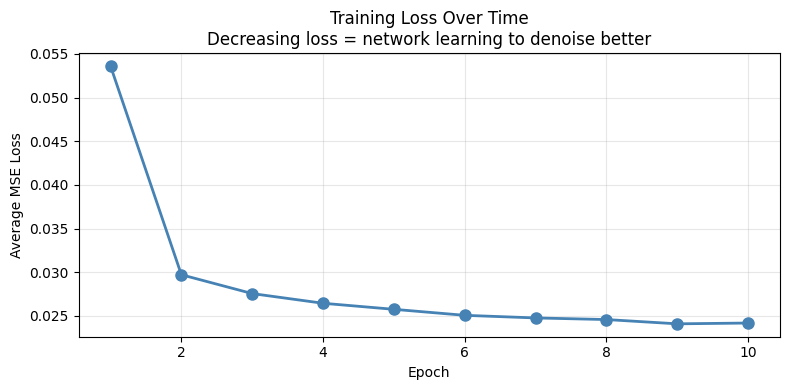

Starting loss: 0.0536
Final loss:    0.0242
Improvement:   54.9%


In [ ]:
optimizer    = torch.optim.Adam(model.parameters(), lr=2e-4)
n_epochs     = 10
loss_history = []

print(f"Starting training for {n_epochs} epochs")
print(f"Each epoch = {len(train_loader)} batches of 128 images")
print(f"Total training steps: {n_epochs * len(train_loader)}")
print()
print("What the loss means:")
print("  High loss = network cannot predict noise well = bad score estimate")
print("  Low loss  = network predicts noise accurately = good score estimate")
print()

for epoch in range(n_epochs):
    model.train()
    epoch_losses = []

    for batch_idx, (images, _) in enumerate(train_loader):
        images = images.to(device)
        batch_size = images.shape[0]

        t = torch.randint(0, T, (batch_size,), device=device).long()

        x_noisy, true_noise = forward_diffusion(images, t, device)

        predicted_noise = model(x_noisy, t)

        loss = F.mse_loss(predicted_noise, true_noise)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        epoch_losses.append(loss.item())

    avg_loss = np.mean(epoch_losses)
    loss_history.append(avg_loss)
    print(f"Epoch {epoch+1:2d}/{n_epochs}  |  "
          f"Average Loss: {avg_loss:.4f}  |  "
          f"Last batch loss: {epoch_losses[-1]:.4f}")

print()

# Plot training loss
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, n_epochs+1), loss_history,
        'o-', color='steelblue', linewidth=2, markersize=8)
ax.set_xlabel('Epoch')
ax.set_ylabel('Average MSE Loss')
ax.set_title('Training Loss Over Time\n'
             'Decreasing loss = network learning to denoise better')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Starting loss: {loss_history[0]:.4f}")
print(f"Final loss:    {loss_history[-1]:.4f}")
print(f"Improvement:   {(1 - loss_history[-1]/loss_history[0])*100:.1f}%")

Generating a digit with the REVERSE process
This walks backwards through all T=1000 timesteps.

Reverse process complete: 7 snapshots saved (noise -> digit).

Using the SAME generated digits as the starting point for the FORWARD process

Forward process complete: noised the SAME 4 generated digits at 6 timesteps.


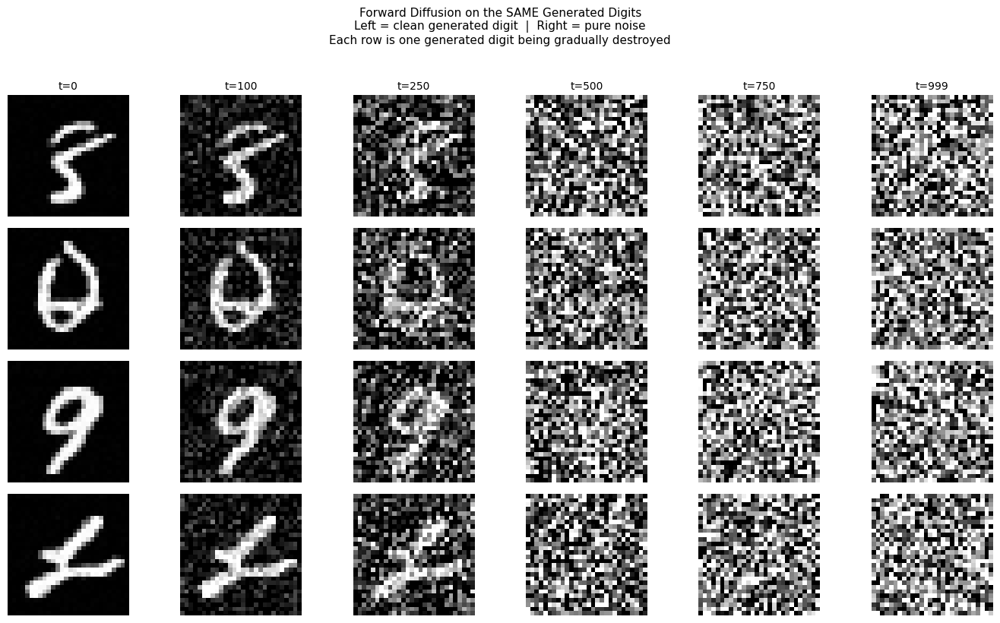

At t=0:   the generated digit is clearly visible (same as reverse output)
At t=999: pure noise, digit completely destroyed


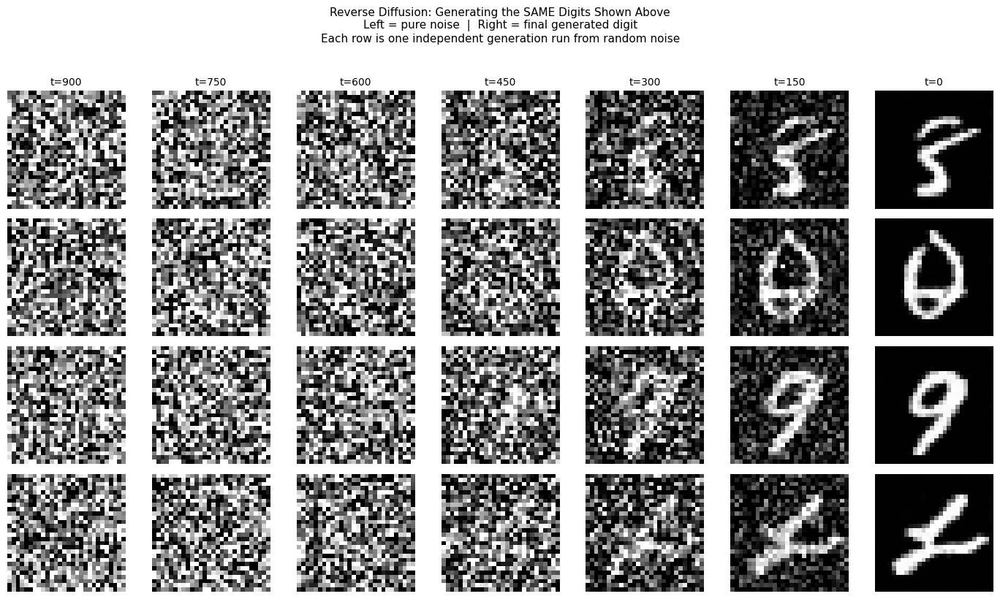

At t=999 (or the largest saved step): pure noise, no digit visible
At t=0:   the exact same digit shown in the forward-process figure

KEY POINT:
Both figures above use the SAME set of digits.
The bottom-right image of the REVERSE figure
is the SAME image as the top-left image of the FORWARD figure,
for each row.


In [ ]:
@torch.no_grad()
def reverse_diffusion_step(model, x_t, t, device):
    batch_size = x_t.shape[0]
    t_tensor   = torch.full((batch_size,), t, device=device, dtype=torch.long)

    predicted_noise = model(x_t, t_tensor)

    alpha_t      = alphas[t]
    alpha_bar_t  = alphas_cumprod[t]
    beta_t       = betas[t]

    coef1 = 1.0 / torch.sqrt(alpha_t)
    coef2 = beta_t / torch.sqrt(1.0 - alpha_bar_t)
    mean  = coef1 * (x_t - coef2 * predicted_noise)

    if t > 0:
        noise = torch.randn_like(x_t)
        sigma = torch.sqrt(beta_t)
        x_prev = mean + sigma * noise
    else:
        x_prev = mean

    return x_prev


@torch.no_grad()
def generate_digits(model, n_samples, image_size, device, save_every=None):
    model.eval()
    x = torch.randn((n_samples, *image_size), device=device)

    snapshots      = []
    snapshot_steps = []

    for t in reversed(range(T)):
        x = reverse_diffusion_step(model, x, t, device)

        if save_every is not None and (t % save_every == 0 or t == 0):
            snapshots.append(x.clone().cpu())
            snapshot_steps.append(t)

    return x, snapshots, snapshot_steps

def forward_diffusion(x0, t, device):
    noise = torch.randn_like(x0)

    sqrt_alpha_bar   = sqrt_alphas_cumprod[t].view(-1, 1, 1, 1)
    sqrt_one_minus   = sqrt_one_minus_alphas_cumprod[t].view(-1, 1, 1, 1)

    x_t = sqrt_alpha_bar * x0 + sqrt_one_minus * noise
    return x_t, noise


print("Generating a digit with the REVERSE process")
print(f"This walks backwards through all T={T} timesteps.\n")

n_gen = 4
final_images, snaps, snap_steps = generate_digits(
    model=model,
    n_samples=n_gen,
    image_size=(1, 28, 28),
    device=device,
    save_every=150
)

print(f"Reverse process complete: {len(snaps)} snapshots saved (noise -> digit).")

print("\nUsing the SAME generated digits as the starting point "
      "for the FORWARD process\n")

sample_images = final_images.to(device)

timesteps_to_show = [0, 100, 250, 500, 750, 999]

forward_snapshots_all = []
for row in range(n_gen):
    img_expanded = sample_images[row].unsqueeze(0)
    row_snapshots = []
    for t_val in timesteps_to_show:
        t_tensor = torch.tensor([t_val], device=device)
        noisy_img, _ = forward_diffusion(img_expanded, t_tensor, device)
        row_snapshots.append(noisy_img[0, 0].cpu().numpy())
    forward_snapshots_all.append(row_snapshots)

print(f"Forward process complete: noised the SAME {n_gen} generated digits "
      f"at {len(timesteps_to_show)} timesteps.")


fig, axes = plt.subplots(n_gen, len(timesteps_to_show), figsize=(14, 8))

for row in range(n_gen):
    for col, t_val in enumerate(timesteps_to_show):
        axes[row, col].imshow(
            forward_snapshots_all[row][col],
            cmap='gray', vmin=-1, vmax=1
        )
        axes[row, col].axis('off')
        if row == 0:
            axes[row, col].set_title(f't={t_val}', fontsize=10)

fig.suptitle(
    'Forward Diffusion on the SAME Generated Digits\n'
    'Left = clean generated digit  |  Right = pure noise\n'
    'Each row is one generated digit being gradually destroyed',
    fontsize=11, y=1.02
)
plt.tight_layout()
plt.show()

print("At t=0:   the generated digit is clearly visible (same as reverse output)")
print("At t=999: pure noise, digit completely destroyed")

fig, axes = plt.subplots(n_gen, len(snap_steps), figsize=(14, 8))

for row in range(n_gen):
    for col, (snap, t_val) in enumerate(zip(snaps, snap_steps)):
        axes[row, col].imshow(
            snap[row, 0].numpy(),
            cmap='gray', vmin=-1, vmax=1
        )
        axes[row, col].axis('off')
        if row == 0:
            axes[row, col].set_title(f't={t_val}', fontsize=10)

fig.suptitle(
    'Reverse Diffusion: Generating the SAME Digits Shown Above\n'
    'Left = pure noise  |  Right = final generated digit\n'
    'Each row is one independent generation run from random noise',
    fontsize=11, y=1.02
)
plt.tight_layout()
plt.show()

print("At t=999 (or the largest saved step): pure noise, no digit visible")
print("At t=0:   the exact same digit shown in the forward-process figure")
print()
print("KEY POINT:")
print("Both figures above use the SAME set of digits.")
print("The bottom-right image of the REVERSE figure")
print("is the SAME image as the top-left image of the FORWARD figure,")
print("for each row.")

Generating 16 new handwritten digits
This runs T=1000 reverse steps



Generating: 100%|██████████| 1000/1000 [00:05<00:00, 194.35it/s]


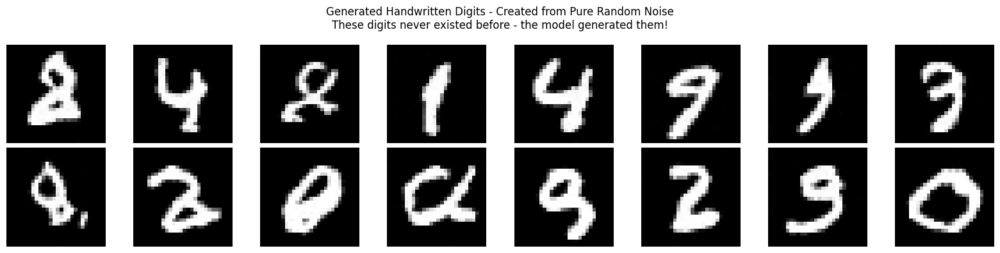

These are brand new digits that were never in the training set
The model learned to generate them purely from the denoising objective


In [ ]:
@torch.no_grad()
def generate_images(model, n_images=16, device='cuda'):
    """
    Start from pure Gaussian noise and follow the learned score
    backward through all T timesteps.
    This is equation 5 - the reverse SDE - applied T times.
    """
    model.eval()

    # Start from pure noise (the starting point of generation)
    x = torch.randn(n_images, 1, 28, 28, device=device)

    # Store intermediate images to show the two phases
    intermediates = {}

    for t_val in tqdm(reversed(range(T)), total=T, desc="Generating"):
        t_batch = torch.full((n_images,), t_val,
                             device=device, dtype=torch.long)

        predicted_noise = model(x, t_batch)

        alpha      = alphas[t_val]
        alpha_bar  = alphas_cumprod[t_val]
        beta       = betas[t_val]

        # Reverse diffusion step
        if t_val > 0:
            noise = torch.randn_like(x)
        else:
            noise = torch.zeros_like(x)

        x = (1 / torch.sqrt(alpha)) * (
            x - ((1 - alpha) / torch.sqrt(1 - alpha_bar)) * predicted_noise
        ) + torch.sqrt(beta) * noise


        if t_val in [999, 800, 600, 400, 200, 100, 50, 0]:
            intermediates[t_val] = x.cpu().clone()

    return x.cpu(), intermediates


print("Generating 16 new handwritten digits")
print("This runs T=1000 reverse steps")
print()

generated, intermediates = generate_images(model, n_images=16, device=device)

# Plot final generated digits
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(generated[i, 0].numpy(), cmap='gray', vmin=-1, vmax=1)
    ax.axis('off')

fig.suptitle(
    'Generated Handwritten Digits - Created from Pure Random Noise\n'
    'These digits never existed before - the model generated them!',
    fontsize=12
)
plt.tight_layout()
plt.show()

print("These are brand new digits that were never in the training set")
print("The model learned to generate them purely from the denoising objective")

Fine-tune on Your Own Face (LoRA)

In [ ]:
!pip install diffusers transformers accelerate peft -q
!pip install torchvision Pillow -q

In [ ]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files
import torchvision.transforms as transforms

# Create a folder to store your images
os.makedirs("my_images", exist_ok=True)

print("UPLOAD YOUR SELFIES NOW")
print("Instructions:")
print("  1. Click 'Choose Files' below")
print("  2. Select 5-10 of your selfie photos")
print("  3. Mix of different expressions/angles is best")
print("  4. JPG or PNG format")
print()

# Upload files
uploaded = files.upload()

# Save uploaded files to folder
image_paths = []
for filename, content in uploaded.items():
    filepath = f"my_images/{filename}"
    with open(filepath, 'wb') as f:
        f.write(content)
    image_paths.append(filepath)
    print(f"Saved: {filename}")

print(f"\nTotal images uploaded: {len(image_paths)}")

UPLOAD YOUR SELFIES NOW
Instructions:
  1. Click 'Choose Files' below
  2. Select 5-10 of your selfie photos
  3. Mix of different expressions/angles is best
  4. JPG or PNG format
  5. Any size is fine — we will resize automatically



Saving WhatsApp Image 2026-07-15 at 22.29.49 (1).jpeg to WhatsApp Image 2026-07-15 at 22.29.49 (1).jpeg
Saving WhatsApp Image 2026-07-15 at 22.29.49 (2).jpeg to WhatsApp Image 2026-07-15 at 22.29.49 (2).jpeg
Saving WhatsApp Image 2026-07-15 at 22.29.49 (3).jpeg to WhatsApp Image 2026-07-15 at 22.29.49 (3).jpeg
Saving WhatsApp Image 2026-07-15 at 22.29.49 (4).jpeg to WhatsApp Image 2026-07-15 at 22.29.49 (4).jpeg
Saving WhatsApp Image 2026-07-15 at 22.29.49 (5).jpeg to WhatsApp Image 2026-07-15 at 22.29.49 (5).jpeg
Saving WhatsApp Image 2026-07-15 at 22.29.49 (6).jpeg to WhatsApp Image 2026-07-15 at 22.29.49 (6).jpeg
Saving WhatsApp Image 2026-07-15 at 22.29.49 (7).jpeg to WhatsApp Image 2026-07-15 at 22.29.49 (7).jpeg
Saving WhatsApp Image 2026-07-15 at 22.29.49 (8).jpeg to WhatsApp Image 2026-07-15 at 22.29.49 (8).jpeg
Saving WhatsApp Image 2026-07-15 at 22.29.49 (9).jpeg to WhatsApp Image 2026-07-15 at 22.29.49 (9).jpeg
Saving WhatsApp Image 2026-07-15 at 22.29.49.jpeg to WhatsApp Im

All images resized to 512x512



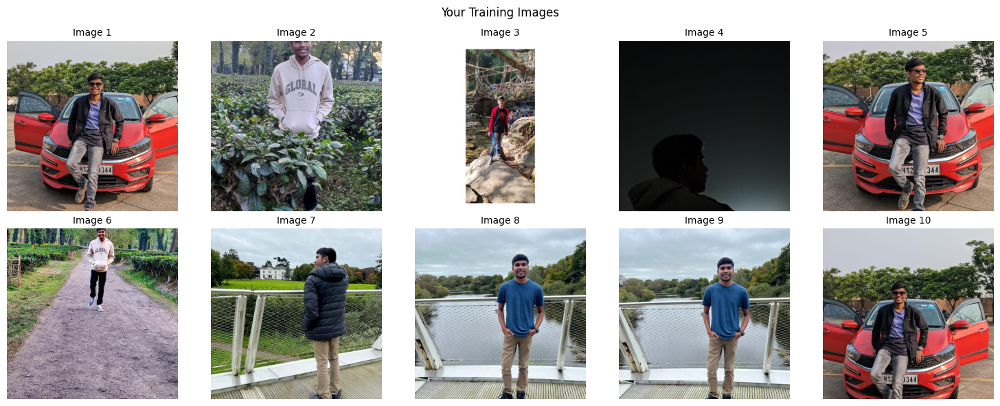

Tips for best results:
- Mix of frontal and slight angle shots
- Different lighting conditions
- Different expressions (smile, neutral, etc)
- Clear face, not too much background clutter


In [ ]:
def load_and_resize(path, size=512):
    """
    Load an image and resize it to size x size.
    Also centre-crop to make it square first.
    """
    img = Image.open(path).convert("RGB")

    # Centre crop to square
    w, h   = img.size
    min_dim = min(w, h)
    left   = (w - min_dim) // 2
    top    = (h - min_dim) // 2
    img    = img.crop((left, top, left + min_dim, top + min_dim))

    img = img.resize((size, size), Image.LANCZOS)
    return img

processed_images = []
for path in image_paths:
    img = load_and_resize(path)
    processed_images.append(img)
    img.save(path)

print(f"All images resized to 512x512")
print()

n_images = len(processed_images)
cols     = min(n_images, 5)
rows     = (n_images + cols - 1) // cols

fig, axes = plt.subplots(rows, cols,
                          figsize=(cols * 3, rows * 3))

if rows == 1 and cols == 1:
    axes = [[axes]]
elif rows == 1:
    axes = [axes]

for i, img in enumerate(processed_images):
    row = i // cols
    col = i % cols
    axes[row][col].imshow(img)
    axes[row][col].axis('off')
    axes[row][col].set_title(f'Image {i+1}', fontsize=10)

# Hide unused subplots
for i in range(n_images, rows * cols):
    row = i // cols
    col = i % cols
    axes[row][col].axis('off')

fig.suptitle(
    'Your Training Images',
    fontsize=12
)
plt.tight_layout()
plt.show()


In [ ]:
# The key idea of fine-tuning for face cloning:
# We give the model a UNIQUE TOKEN (a made-up word) that
# represents YOU specifically
# For example: "sks person"
# Then we fine-tune the model so that whenever it sees "sks"
# it generates YOUR face
#
# This is the core of DreamBooth/LoRA fine-tuning:
# Associate a unique token with your identity

# Your unique token this is a made-up word that will mean "you"
# Change this to anything you like - just make it unique
UNIQUE_TOKEN    = "sks"
CLASS_TOKEN     = "person"
INSTANCE_PROMPT = f"a photo of {UNIQUE_TOKEN} {CLASS_TOKEN}"
CLASS_PROMPT    = f"a photo of a {CLASS_TOKEN}"

print("Fine-tuning configuration:")
print()
print(f"Unique token:     '{UNIQUE_TOKEN}'")
print(f"Class token:      '{CLASS_TOKEN}'")
print(f"Instance prompt:  '{INSTANCE_PROMPT}'")
print(f"Class prompt:     '{CLASS_PROMPT}'")
print()
print("How this works:")
print(f"  The model will learn that '{UNIQUE_TOKEN}' = your face")
print(f"  After fine-tuning you can generate prompts like:")
print(f"  'a photo of {UNIQUE_TOKEN} {CLASS_TOKEN} on a beach'")
print(f"  'a photo of {UNIQUE_TOKEN} {CLASS_TOKEN} wearing glasses'")
print(f"  'a photo of {UNIQUE_TOKEN} {CLASS_TOKEN} as an astronaut'")
print(f"  And it will generate YOUR face in those scenarios")

Fine-tuning configuration:

Unique token:     'sks'
Class token:      'person'
Instance prompt:  'a photo of sks person'
Class prompt:     'a photo of a person'

How this works:
  The model will learn that 'sks' = your face
  After fine-tuning you can generate prompts like:
  'a photo of sks person on a beach'
  'a photo of sks person wearing glasses'
  'a photo of sks person as an astronaut'
  And it will generate YOUR face in those scenarios


In [ ]:
!pip uninstall torchao -y -q
!pip install torchao==0.16.0 -q
!pip install peft --upgrade -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 111.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 775.8/775.8 kB 45.5 MB/s eta 0:00:00


In [ ]:
from diffusers import StableDiffusionPipeline, DDPMScheduler
from peft import LoraConfig, get_peft_model
from transformers import CLIPTokenizer, CLIPTextModel
import torch
import torch.nn.functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")
print()

# Load Stable Diffusion 1.5 as our base model
# This is a full text-to-image model trained on billions of images
# We will fine-tune it to also know what you look like
MODEL_NAME = "runwayml/stable-diffusion-v1-5"

print(f"Loading base model: {MODEL_NAME}")

pipeline = StableDiffusionPipeline.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    safety_checker=None
)
pipeline = pipeline.to(device)

# Extract components we need for training
unet      = pipeline.unet
vae       = pipeline.vae
tokenizer = pipeline.tokenizer
text_encoder = pipeline.text_encoder
noise_scheduler = DDPMScheduler.from_pretrained(
    MODEL_NAME, subfolder="scheduler"
)

# Setup LoRA on the UNet
# LoRA adds small trainable matrices to the attention layers
# Instead of training all 860 million parameters
# LoRA only trains ~1 million parameters (about 0.1%)
# This is why it works with so few images and so little memory

lora_config = LoraConfig(
    r=16,                    # rank - higher = more capacity but more memory
    lora_alpha=32,           # scaling factor
    target_modules=[         # which layers to apply LoRA to
        "to_q",              # query projection in attention
        "to_k",              # key projection in attention
        "to_v",              # value projection in attention
        "to_out.0"           # output projection in attention
    ],
    lora_dropout=0.1,        # dropout for regularisation
    bias="none"
)

# Apply LoRA to the UNet
unet = get_peft_model(unet, lora_config)
unet.print_trainable_parameters()

print()
print("Only the LoRA matrices will be trained")
print("The rest of the model stays frozen (preserves general knowledge)")

Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


Using device: cuda

Loading base model: runwayml/stable-diffusion-v1-5


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


trainable params: 3,188,736 || all params: 862,709,700 || trainable%: 0.3696

LoRA configured!
Only the LoRA matrices will be trained
The rest of the model stays frozen (preserves general knowledge)


In [ ]:
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

class FaceDataset(Dataset):
    """
    Simple dataset that loads your face images
    and pairs them with the instance prompt.
    Each image is:
      1. Loaded and converted to RGB
      2. Resized to 512x512
      3. Converted to tensor in range [-1, 1]
      4. Paired with the text prompt describing you
    """
    def __init__(self, image_paths, tokenizer, prompt, size=512):
        self.image_paths = image_paths
        self.tokenizer   = tokenizer
        self.prompt      = prompt
        self.size        = size

        self.transform = T.Compose([
            T.Resize((size, size)),
            T.CenterCrop(size),
            T.ToTensor(),
            T.Normalize([0.5], [0.5])  # rescale to [-1, 1]
        ])

    def __len__(self):
        # Repeat images to get more training steps
        return len(self.image_paths) * 20

    def __getitem__(self, idx):
        # Cycle through images
        img_idx = idx % len(self.image_paths)
        img     = Image.open(self.image_paths[img_idx]).convert("RGB")
        img     = self.transform(img)

        # Tokenise the text prompt
        tokens = self.tokenizer(
            self.prompt,
            padding="max_length",
            max_length=self.tokenizer.model_max_length,
            truncation=True,
            return_tensors="pt"
        )

        return {
            "pixel_values": img,
            "input_ids":    tokens.input_ids[0]
        }

dataset = FaceDataset(
    image_paths=image_paths,
    tokenizer=tokenizer,
    prompt=INSTANCE_PROMPT,
    size=512
)

dataloader = DataLoader(
    dataset,
    batch_size=1,
    shuffle=True
)

print(f"Real images:     {len(image_paths)}")
print(f"Training steps:  {len(dataset)} (images repeated 20 times)")
print(f"Instance prompt: '{INSTANCE_PROMPT}'")
print()
print("Each training step shows the model:")
print("- A noisy version of your face")
print("- The text prompt describing you")
print("- The model learns to associate the prompt with your face")

Dataset created!
Real images:     10
Training steps:  200 (images repeated 20 times)
Instance prompt: 'a photo of sks person'

Each training step shows the model:
- A noisy version of your face
- The text prompt describing you
- The model learns to associate the prompt with your face


Starting LoRA fine-tuning for 400 steps
What is happening during training:
  Step 1: Encode your face image into latent space (VAE)
  Step 2: Add noise to the latent (forward process)
  Step 3: Encode the text prompt (CLIP text encoder)
  Step 4: UNet predicts the noise given image + text
  Step 5: Loss = ||predicted noise - true noise||²
  Step 6: Update only the LoRA weights

Step   50/400  |  Loss: 0.1742
Step  100/400  |  Loss: 0.1981
Step  150/400  |  Loss: 0.1198
Step  200/400  |  Loss: 0.1719
Step  250/400  |  Loss: 0.1636
Step  300/400  |  Loss: 0.1450
Step  350/400  |  Loss: 0.1559
Step  400/400  |  Loss: 0.1351


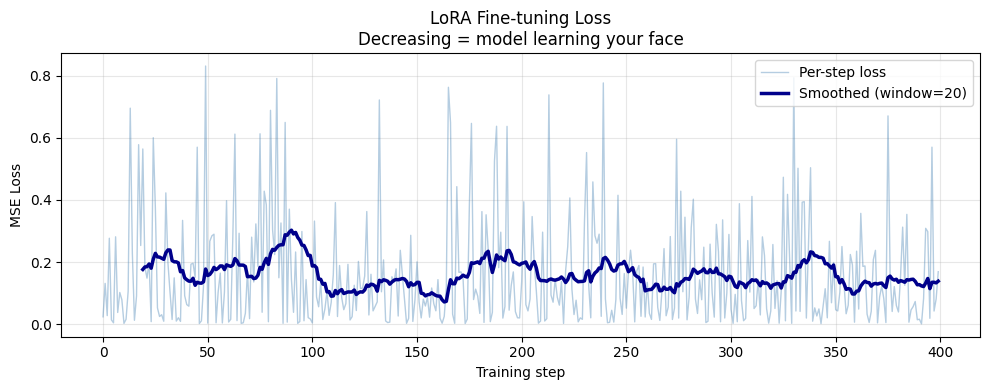

Starting loss: 0.0240
Final loss:    0.1690


In [ ]:
# Training loop
# but now the model also sees the TEXT PROMPT
# So it learns: "when I see 'sks person' generate THIS face"

optimizer = torch.optim.AdamW(
    unet.parameters(),
    lr=1e-4,
    weight_decay=1e-2
)

# Training settings
n_steps       = 400    # number of training steps
# More steps = better results but longer training

loss_history  = []
vae.requires_grad_(False)           # freeze VAE
text_encoder.requires_grad_(False)  # freeze text encoder
unet.train()

print(f"Starting LoRA fine-tuning for {n_steps} steps")
print("What is happening during training:")
print("  Step 1: Encode your face image into latent space (VAE)")
print("  Step 2: Add noise to the latent (forward process)")
print("  Step 3: Encode the text prompt (CLIP text encoder)")
print("  Step 4: UNet predicts the noise given image + text")
print("  Step 5: Loss = ||predicted noise - true noise||²")
print("  Step 6: Update only the LoRA weights")
print()

for step in range(n_steps):

    # Get a batch
    batch = next(iter(dataloader))
    pixel_values = batch["pixel_values"].to(device,
                         dtype=torch.float16 if device=="cuda" else torch.float32)
    input_ids    = batch["input_ids"].to(device)

    # Step 1: Encode images into VAE latent space
    # Stable Diffusion works in latent space (64x64) not pixel space (512x512)
    # This is 8x smaller and much faster to train on
    with torch.no_grad():
        latents = vae.encode(pixel_values).latent_dist.sample()
        latents = latents * vae.config.scaling_factor

    # Step 2: Add noise (forward process)
    noise     = torch.randn_like(latents)
    timesteps = torch.randint(
        0, noise_scheduler.config.num_train_timesteps,
        (latents.shape[0],), device=device
    ).long()
    noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

    # Step 3: Encode text prompt
    with torch.no_grad():
        text_embeddings = text_encoder(input_ids)[0]

    # Step 4: Predict noise with UNet (conditioned on text)
    noise_pred = unet(
        noisy_latents,
        timesteps,
        encoder_hidden_states=text_embeddings
    ).sample

    # Step 5: Compute loss
    loss = F.mse_loss(noise_pred.float(), noise.float())

    # Step 6: Update LoRA weights only
    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(unet.parameters(), 1.0)
    optimizer.step()

    loss_history.append(loss.item())

    # Print progress every 50 steps
    if (step + 1) % 50 == 0:
        avg_loss = np.mean(loss_history[-50:])
        print(f"Step {step+1:4d}/{n_steps}  |  Loss: {avg_loss:.4f}")

# Plot training loss
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(loss_history, color='steelblue', alpha=0.4, linewidth=1, label='Per-step loss')
# Smooth loss curve
window = 20
smooth = np.convolve(loss_history, np.ones(window)/window, mode='valid')
ax.plot(range(window-1, len(loss_history)), smooth,
        color='darkblue', linewidth=2.5, label=f'Smoothed (window={window})')
ax.set_xlabel('Training step')
ax.set_ylabel('MSE Loss')
ax.set_title('LoRA Fine-tuning Loss\nDecreasing = model learning your face')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Starting loss: {loss_history[0]:.4f}")
print(f"Final loss:    {loss_history[-1]:.4f}")

In [ ]:
from diffusers import StableDiffusionImg2ImgPipeline
import random


img2img_pipeline = StableDiffusionImg2ImgPipeline(
    vae=pipeline.vae,
    text_encoder=pipeline.text_encoder,
    tokenizer=pipeline.tokenizer,
    unet=pipeline.unet,
    scheduler=pipeline.scheduler,
    safety_checker=None,
    feature_extractor=None,
    requires_safety_checker=False,
).to(device)

generator = torch.Generator(device=device).manual_seed(42)

generation_prompts = [
    f"a photo of {UNIQUE_TOKEN} {CLASS_TOKEN}, natural lighting, high quality",
    f"a photo of {UNIQUE_TOKEN} {CLASS_TOKEN} smiling, outdoor background",
    f"a photo of {UNIQUE_TOKEN} {CLASS_TOKEN} on a beach at sunset",
    f"a photo of {UNIQUE_TOKEN} {CLASS_TOKEN} in a forest, cinematic",
    f"a photo of {UNIQUE_TOKEN} {CLASS_TOKEN} wearing a hat",
    f"a photo of {UNIQUE_TOKEN} {CLASS_TOKEN} in professional attire",
    f"a portrait of {UNIQUE_TOKEN} {CLASS_TOKEN}, oil painting style",
    f"a photo of {UNIQUE_TOKEN} {CLASS_TOKEN} as an astronaut in space",
]

generated_clones = []

for i, prompt in enumerate(generation_prompts):
    print(f"Generating {i+1}/{len(generation_prompts)}: '{prompt}'")

    init_image = random.choice(processed_images)

    with torch.autocast(device):
        image = img2img_pipeline(
            prompt=prompt,
            image=init_image,
            strength=0.65,
                                        #

            negative_prompt="blurry, bad quality, distorted face, ugly, different person",
            num_inference_steps=50,
            guidance_scale=7.5,
            generator=generator
        ).images[0]

    generated_clones.append((prompt, image))


Generating images similar to your real photos, in new scenarios
Generating 1/8: 'a photo of sks person, natural lighting, high quality'


  0%|          | 0/32 [00:00<?, ?it/s]

Generating 2/8: 'a photo of sks person smiling, outdoor background'


  0%|          | 0/32 [00:00<?, ?it/s]

Generating 3/8: 'a photo of sks person on a beach at sunset'


...

Generating 7/8: 'a portrait of sks person, oil painting style'


  0%|          | 0/32 [00:00<?, ?it/s]

Generating 8/8: 'a photo of sks person as an astronaut in space'


  0%|          | 0/32 [00:00<?, ?it/s]


Done! Each generated image now starts from one of your real photos,
so results should look similar to you (same rough pose/features)
while showing you in a new scenario, rather than a fully different face.


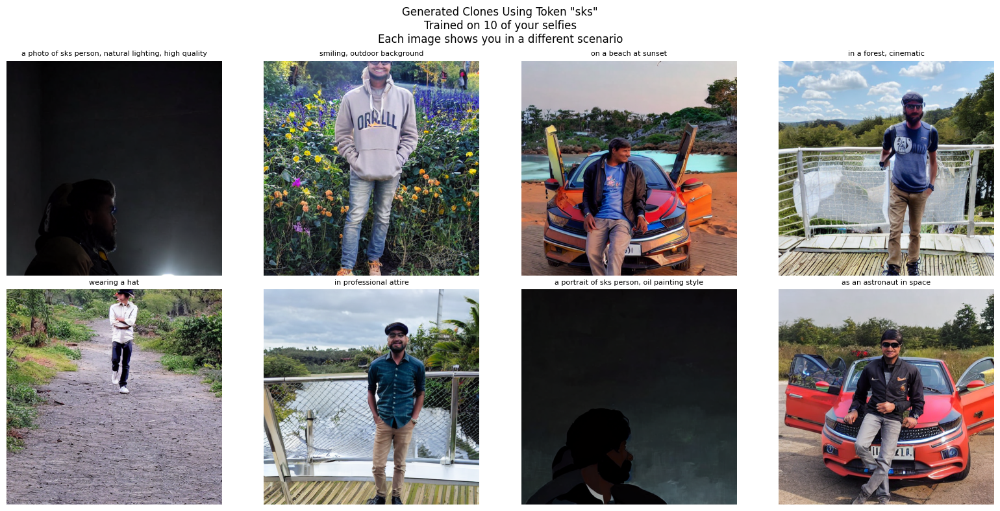

In [ ]:
# Show all generated clones in a grid
n_generated = len(generated_clones)
cols        = 4
rows        = (n_generated + cols - 1) // cols

fig, axes = plt.subplots(rows, cols,
                          figsize=(cols * 4, rows * 4))
axes = axes.ravel()

for i, (prompt, img) in enumerate(generated_clones):
    axes[i].imshow(img)
    axes[i].axis('off')
    # Wrap long prompt text
    short_prompt = prompt.replace(f"a photo of {UNIQUE_TOKEN} {CLASS_TOKEN} ", "")
    short_prompt = short_prompt.replace(f"a portrait of {UNIQUE_TOKEN} {CLASS_TOKEN} ", "")
    axes[i].set_title(short_prompt, fontsize=8, wrap=True)

# Hide unused subplots
for i in range(n_generated, len(axes)):
    axes[i].axis('off')

fig.suptitle(
    f'Generated Clones Using Token "{UNIQUE_TOKEN}"\n'
    f'Trained on {len(image_paths)} of your selfies\n'
    f'Each image shows you in a different scenario',
    fontsize=12
)
plt.tight_layout()
plt.show()

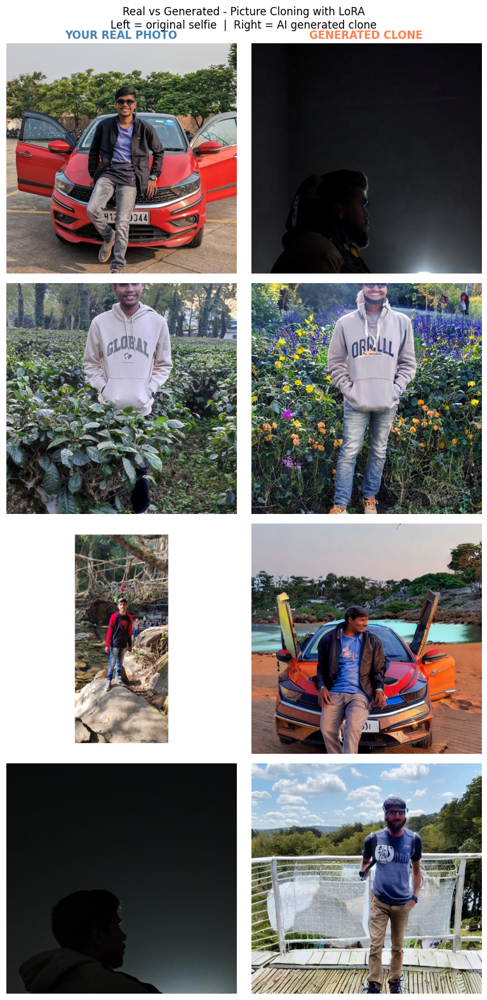

The model has learned your facial features from just a few photos
and can now generate you in completely new scenarios


In [ ]:
n_compare = min(4, len(processed_images))
fig, axes = plt.subplots(n_compare, 2,
                          figsize=(8, n_compare * 4))

for i in range(n_compare):
    # Left: your real photo
    axes[i, 0].imshow(processed_images[i])
    axes[i, 0].axis('off')
    if i == 0:
        axes[i, 0].set_title('YOUR REAL PHOTO',
                              fontsize=12, color='steelblue',
                              fontweight='bold')

    # Right: generated clone
    _, gen_img = generated_clones[i]
    axes[i, 1].imshow(gen_img)
    axes[i, 1].axis('off')
    if i == 0:
        axes[i, 1].set_title('GENERATED CLONE',
                              fontsize=12, color='coral',
                              fontweight='bold')

fig.suptitle(
    'Real vs Generated - Picture Cloning with LoRA\n'
    'Left = original selfie,Right = AI generated clone',
    fontsize=12
)
plt.tight_layout()
plt.show()

print("The model has learned your facial features from just a few photos")
print("and can now generate you in completely new scenarios")